# Glossy surface height from polarimetric measurements

This notebook actively reconstructs the complete bound author observation stack using local executable mathematics. It distinguishes captured observations, the independently rerun author method, and fresh cleaned-code measurements. **No independently measured ground-truth height is available.** Upstream agreement is numerical reproduction rather than a physical accuracy measurement.

In [1]:
from pathlib import Path
import os, sys, time, json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').is_dir():
    root=root.parent
assert (root/'data/raw_data.npz').is_file(), 'Run from task or notebooks directory'
sys.path.insert(0,str(root))
from src.preprocessing import load_observations, decompose
from src.solvers import reconstruct
from src.visualization import metrics, image_panel
review=os.environ.get('NB_REVIEW_DIR')
def show(fig,name):
    if review:
        Path(review).mkdir(parents=True,exist_ok=True)
        fig.savefig(Path(review)/(name+'.png'),dpi=130,bbox_inches='tight')
    plt.show()
    plt.close(fig)
images,angles,mask,specular=load_observations(root/'data/raw_data.npz')
print('Image dimensions:',images.shape,'foreground pixels:',mask.sum(),'specular pixels:',specular.sum())
print('Polariser angle range [rad]:',angles.min(),angles.max())


Image dimensions: (457, 235, 36) foreground pixels: 74331 specular pixels: 1179
Polariser angle range [rad]: 0.0 2.9670597283903604


## 1. Observations and physical acquisition

A rotating analyser records $I(\alpha)=U[1+\rho\cos(2\alpha-2\phi)]$, with mean intensity $U$, degree of linear polarisation $\rho$, phase $\phi$ modulo $\pi$ and analyser angle $\alpha$ in radians. Each displayed image is an actual captured frame. The masks are author acquisition annotations, not reconstructed height. Axes retain all 457 rows and 235 columns. Polariser angles increase clockwise from image-up; geometric y increases upward.

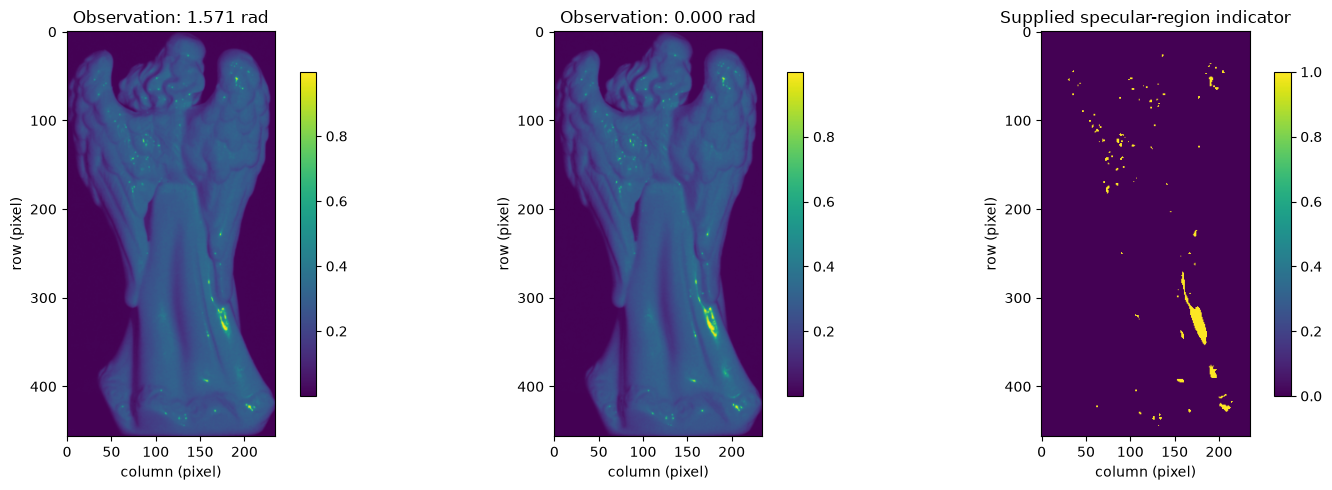

In [2]:
show(image_panel([images[:,:,0],images[:,:,9],specular.astype(float)],
                 [f'Observation: {angles[0]:.3f} rad',f'Observation: {angles[9]:.3f} rad','Supplied specular-region indicator']), '01_observations')


## 2. Reference role and fresh reconstruction

The archived upstream result was computed twice on these exact observations using the published mixed-reflection height formulation in GNU Octave. It is a **method reference**, not ground truth. The following call computes a new result from public observations. The optical normal is $\nu=(-p,-q,1)/\sqrt{1+p^2+q^2}$, where $p=\partial_x z$ and $q=\partial_y z$ are height slopes, x points right and y points up. Height z uses pixel units; the first row-major foreground value anchors the integration gauge.

Fresh reconstruction seconds: 4.2521228000405245
Upstream runtime seconds: 24.64886498451233
Fresh versus upstream: {'ncc': 1.0000000000000016, 'nrmse': 7.32920154545267e-12}
Estimated light: [0.08305138 0.         0.29067983] alternations: 9


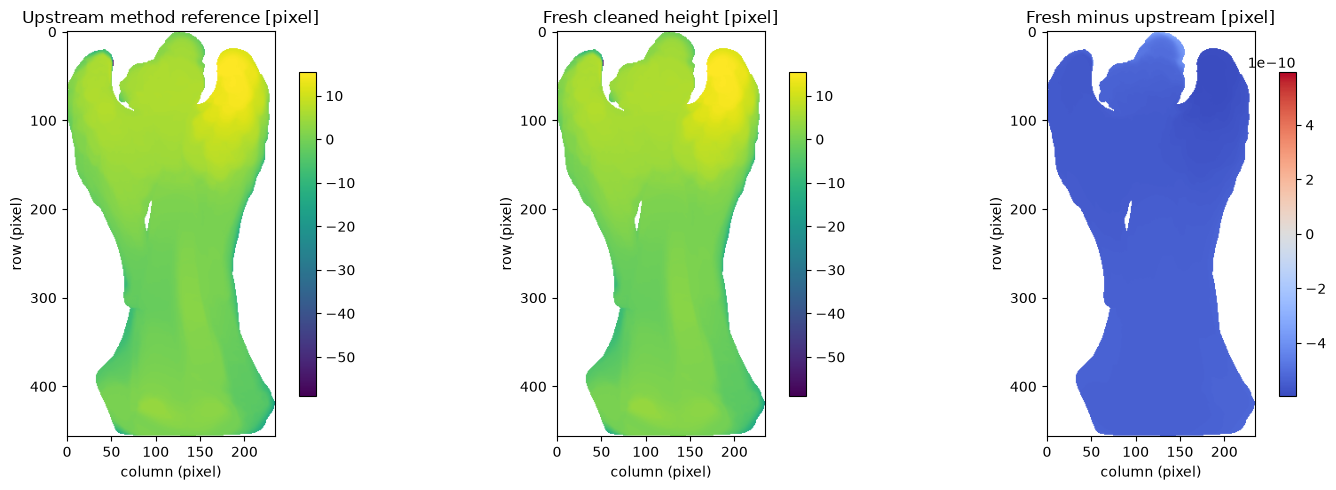

In [3]:
start=time.perf_counter()
height,diagnostics=reconstruct(images,angles,mask,specular)
fresh_seconds=time.perf_counter()-start
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as z:
    upstream=z['height'][0]
    upstream_seconds=float(z['runtime_seconds'].ravel()[0])
comparison=metrics(height,upstream,mask)
print('Fresh reconstruction seconds:',fresh_seconds)
print('Upstream runtime seconds:',upstream_seconds)
print('Fresh versus upstream:',comparison)
print('Estimated light:',diagnostics['light'],'alternations:',diagnostics['light_iterations'])
show(image_panel([upstream,height,height-upstream],['Upstream method reference [pixel]','Fresh cleaned height [pixel]','Fresh minus upstream [pixel]'],mask,signed=[False,False,True],shared_groups=[(0,1)]), '02_fresh_reference')
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=height[None])


## 3. Polarisation and geometric inference

The sinusoid fit is linear in $[U,U\rho\cos 2\phi,U\rho\sin 2\phi]$. The diffuse Fresnel law is inverted at assumed refractive index 1.5, while the supplied specular region uses the increasing branch of the specular Fresnel curve. Diffuse azimuths have a binary ambiguity. Alternating ambiguity selection and scalar light fitting resolves this jointly with a spatial height formulation. The direction (2,0,7) is calibrated; its intensity/albedo factor is estimated from observations. Phase panels use radians and retain the physical distinction between diffuse and specular conventions.

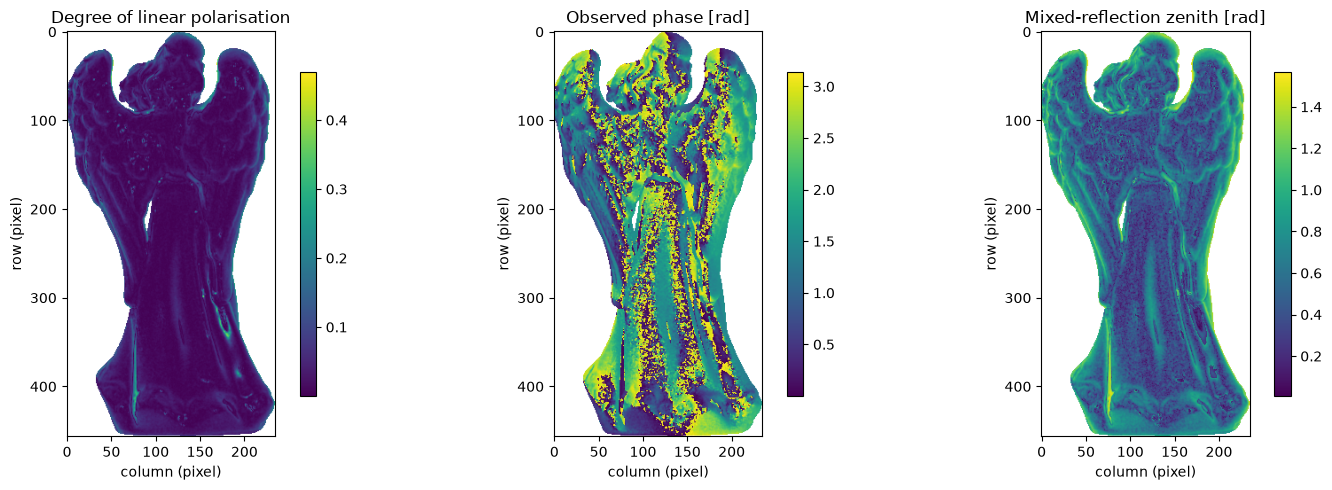

In [4]:
show(image_panel([diagnostics['rho'],diagnostics['phase'],diagnostics['theta']],
                 ['Degree of linear polarisation','Observed phase [rad]','Mixed-reflection zenith [rad]'],mask), '03_polarimetric_fields')


## 4. Objective residuals and measured comparisons

The method solves $\min_z\|Cz-d\|_2^2$. C includes phase, shading or specular halfway constraints, masked finite-difference derivatives and Laplacian smoothing. The additive height gauge is one additional row. This is an unweighted model residual, not a calibrated chi-square statistic. Separately, the forward sinusoid residual measures how well the captured polarimetric stack fits its acquisition modulation. NCC is uncentred cosine similarity; NRMSE uses the reference dynamic range on the public foreground mask. No alignment or rescaling is applied.

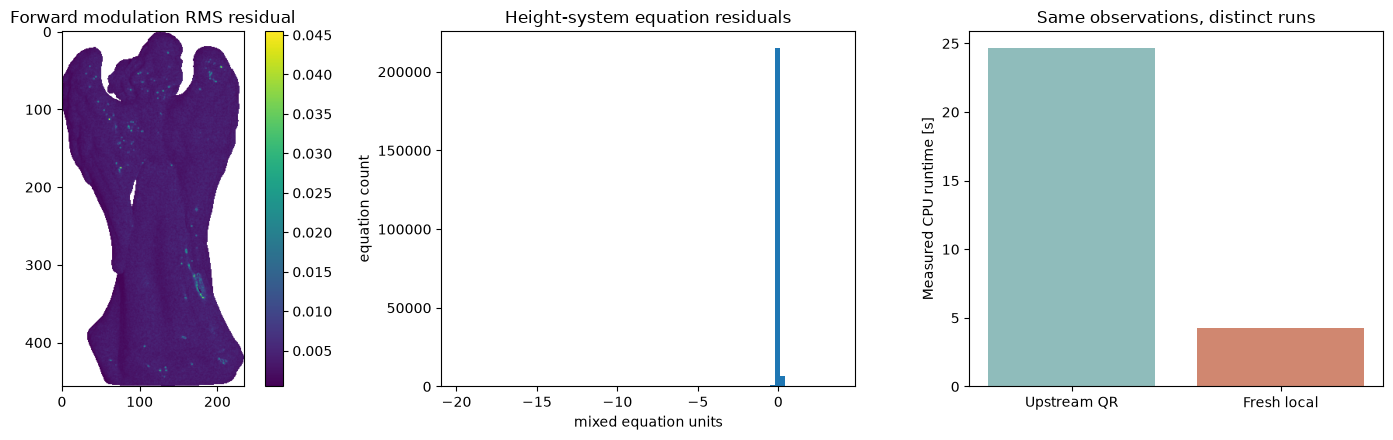

Equation residual L2: 38.04728280554016
Stationarity residual L2: 4.050681215528969e-13
Masked modulation RMS: 0.004026827287256894
method | NCC versus upstream | dynamic-range NRMSE
fresh cleaned | 1.0000000000000016 | 7.32920154545267e-12


In [5]:
r=diagnostics['rho'];ph=diagnostics['phase'];u=diagnostics['intensity']
predicted=u[:,:,None]*(1+r[:,:,None]*np.cos(2*(angles[None,None,:]-ph[:,:,None])))
modulation_rmse=np.sqrt(np.mean((predicted-images)**2,axis=2))
fig,axs=plt.subplots(1,3,figsize=(15,4.5))
artist=axs[0].imshow(np.ma.array(modulation_rmse,mask=~mask));fig.colorbar(artist,ax=axs[0]);axs[0].set_title('Forward modulation RMS residual')
axs[1].hist(diagnostics['residual'],bins=80);axs[1].set_title('Height-system equation residuals');axs[1].set_xlabel('mixed equation units');axs[1].set_ylabel('equation count')
axs[2].bar(['Upstream QR','Fresh local'],[upstream_seconds,fresh_seconds],color=['#8fbcbb','#d08770']);axs[2].set_ylabel('Measured CPU runtime [s]');axs[2].set_title('Same observations, distinct runs')
fig.tight_layout();show(fig,'04_residuals_and_metrics')
print('Equation residual L2:',np.linalg.norm(diagnostics['residual']))
print('Stationarity residual L2:',np.linalg.norm(diagnostics['normal_residual']))
print('Masked modulation RMS:',np.sqrt(np.mean((predicted-images)[mask]**2)))
print('method | NCC versus upstream | dynamic-range NRMSE')
print('fresh cleaned |',comparison['ncc'],'|',comparison['nrmse'])


## 5. Computed smoothing ablation

The standard method weights each interior Laplacian equation by 0.1, giving squared regularization weight 0.01. This ablation actively reconstructs with that weight set to zero while retaining all images, masks, optical constraints and the same integration gauge. Its role is to inspect sensitivity to the spatial prior; agreement with the standard result is not an independent truth metric. The author demo contains a single active height method, preserved here; no absent comparison is filled with a cached surface or zeros.

Fresh zero-smoothing ablation: {'ncc': 0.7560594582502794, 'nrmse': 0.0751066167657646} seconds: 5.445533599995542


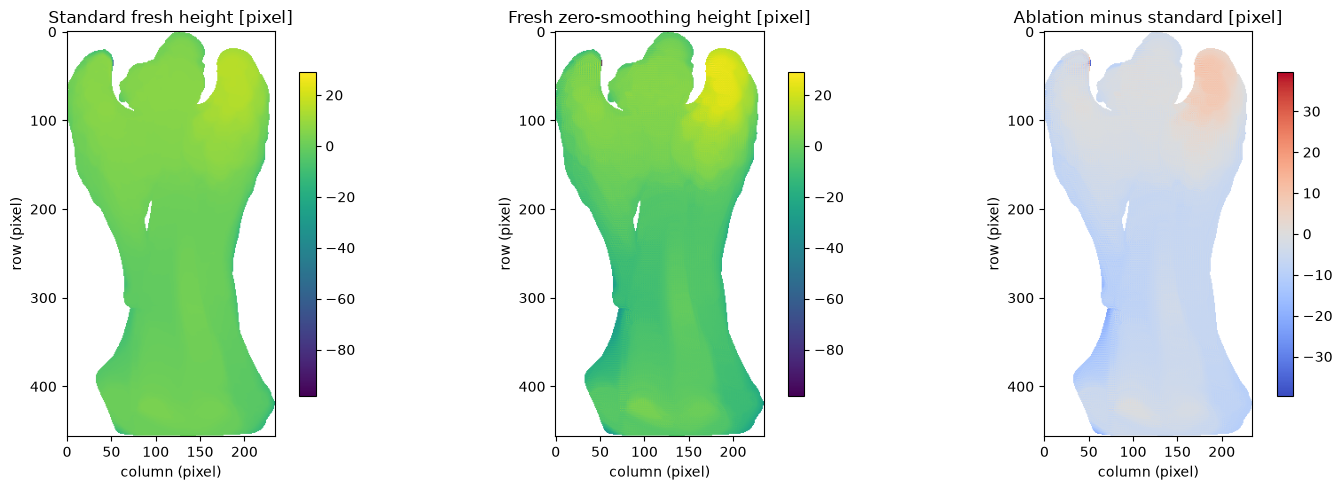

In [6]:
start=time.perf_counter()
ablated,ablation_info=reconstruct(images,angles,mask,specular,smoothing=0.)
ablation_seconds=time.perf_counter()-start
ablation_metrics=metrics(ablated,upstream,mask)
print('Fresh zero-smoothing ablation:',ablation_metrics,'seconds:',ablation_seconds)
show(image_panel([height,ablated,ablated-height],['Standard fresh height [pixel]','Fresh zero-smoothing height [pixel]','Ablation minus standard [pixel]'],mask,signed=[False,False,True],shared_groups=[(0,1)]),'05_smoothing_ablation')


## 6. Computed noise robustness and conclusion

Two reproducible, artificial additive intensity perturbations are applied to all original image dimensions. Each perturbed stack is actively reconstructed; no clean target is supplied to the reconstruction. The seed controls only this maintainer sensitivity experiment and is not a hidden object definition. Changes are measured against the fresh unperturbed result. Real acquisition noise variance is unknown, so these perturbations illustrate algorithm sensitivity rather than an experimentally calibrated robustness guarantee. The main conclusion is upstream numerical reproduction on the full bound acquisition, with physical accuracy limited by the unvalidated reflection and uniform-albedo approximations.

Controlled perturbations compared with fresh unperturbed result:
[
  {
    "intensity_sigma": 0.0001,
    "seconds": 5.510033399972599,
    "ncc": 0.999982632655424,
    "nrmse": 0.00039361920502485674
  },
  {
    "intensity_sigma": 0.001,
    "seconds": 5.479403499979526,
    "ncc": 0.9980959089180436,
    "nrmse": 0.004318419407314745
  }
]


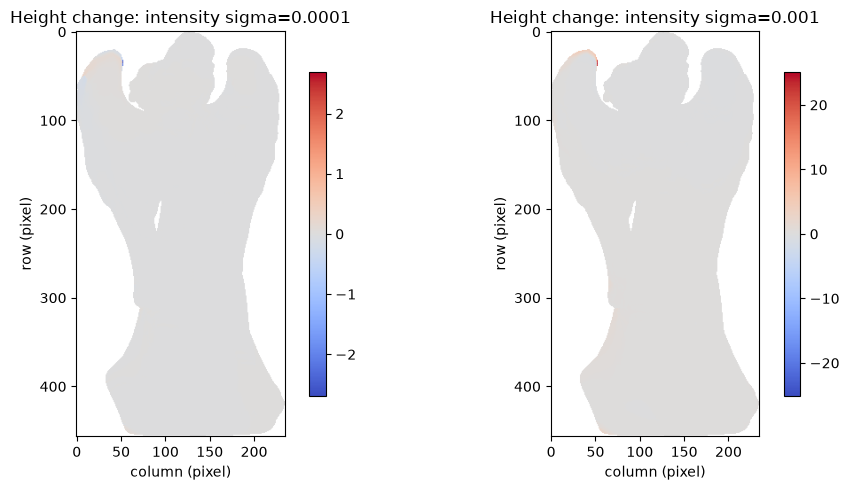

In [7]:
rng=np.random.default_rng(20261026)
noise_levels=[0.0001,0.001]
robustness=[];noisy_results=[]
for sigma in noise_levels:
    perturbed=images+sigma*rng.standard_normal(images.shape)
    start=time.perf_counter()
    estimate,info=reconstruct(perturbed,angles,mask,specular)
    robustness.append(dict(intensity_sigma=sigma,seconds=time.perf_counter()-start,**metrics(estimate,height,mask)))
    noisy_results.append(estimate)
print('Controlled perturbations compared with fresh unperturbed result:')
print(json.dumps(robustness,indent=2))
show(image_panel([noisy_results[0]-height,noisy_results[1]-height],['Height change: intensity sigma=0.0001','Height change: intensity sigma=0.001'],mask,signed=[True,True]),'06_noise_robustness')
summary=dict(fresh_runtime_seconds=fresh_seconds,upstream_runtime_seconds=upstream_seconds,fresh_vs_upstream=comparison,ablation=ablation_metrics,ablation_runtime_seconds=ablation_seconds,robustness=robustness,equation_residual_l2=float(np.linalg.norm(diagnostics['residual'])),stationarity_l2=float(np.linalg.norm(diagnostics['normal_residual'])))
if review:
    (Path(review)/'fresh_notebook_measurements.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
assert np.isfinite(height).all() and comparison['nrmse']<1e-7


### Published halfway approximation: independent scale check

The paper folds albedo into the light vector in its shading equation and then uses that scaled vector in its specular halfway equation. The author code does the same. This is an explicit physical limitation: a specular halfway direction would ordinarily depend on the unit light direction, whereas the selected approximation changes with intensity scale. The diagnostic below evaluates both formulas at the same calibrated direction; it is an analytic model check, not an extra reconstruction or measured ground truth. We preserve the published approximation rather than silently changing the selected method.

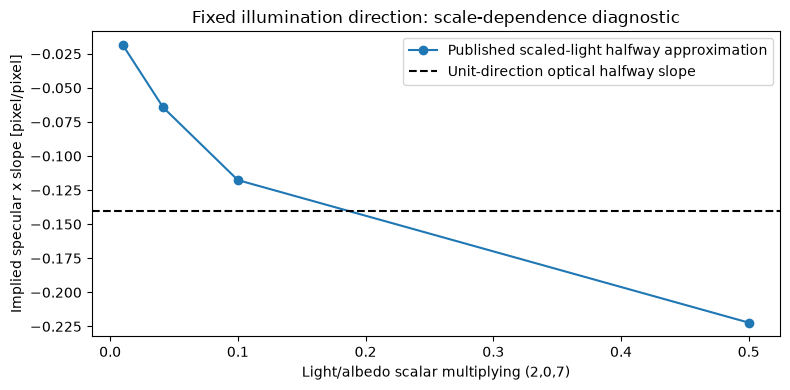

Published approximate slopes: [-0.01869159 -0.064347   -0.11764706 -0.22222222]
Unit-direction optical slope: -0.14005494464025914


In [8]:
direction=np.array([2.,0.,7.]);view=np.array([0.,0.,1.])
scales=np.array([.01,.04152569,.1,.5])
scaled=scales[:,None]*direction
published_half=scaled+view
physical_half=direction/np.linalg.norm(direction)+view
published_slope=-published_half[:,0]/published_half[:,2]
physical_slope=-physical_half[0]/physical_half[2]
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(scales,published_slope,'o-',label='Published scaled-light halfway approximation')
ax.axhline(physical_slope,color='black',linestyle='--',label='Unit-direction optical halfway slope')
ax.set_xlabel('Light/albedo scalar multiplying (2,0,7)')
ax.set_ylabel('Implied specular x slope [pixel/pixel]')
ax.set_title('Fixed illumination direction: scale-dependence diagnostic')
ax.legend();fig.tight_layout();show(fig,'07_halfway_scale_check')
print('Published approximate slopes:',published_slope)
print('Unit-direction optical slope:',physical_slope)
